# RAVE-VL v3 · Portion 1 — pre-stage (CPU work + OpenCLIP on the GPU when one is present)

Every cell prints and logs **wall time, CPU time (kernel + worker processes), cores used, GPU busy time and GPU
energy** to `rave_work/logs/time_ledger.jsonl`. The 7-hour A100 clock is *not* started here (Portion 2 starts it).

| Step | What | Device | Output |
|---|---|---|---|
| P1.1 | `load_dataset("MMMU/MMMU_Pro", "standard (10 options)")` → the single `test` split (1,730 rows) | CPU | dataset |
| P1.2 | Parse question / options (2–12) / answer / `<image k>` refs; dump raw image bytes + SHA-1 | CPU | `meta/`, `raw/` |
| P1.3–4 | Global images at 128 / 256 / 512 / 1024 tokens + native; image statistics; crop candidates | CPU (all usable cores) | `global/` |
| P1.5 | OpenCLIP ViT-L/14 ranking of every candidate vs. question + options | **GPU fp16** (CPU fallback) | ranked candidates |
| P1.6 | Materialise crops: top-1/2/3, random (A2), 4 quadrants (B1), token-matched up-scaled global (B2) | CPU threads | `crops/` |
| P1.7 | 5-fold × 3-repeat folds, stratified by subject, grouped by shared images (no leakage) | CPU | `fold_r*` |
| P1.8 | **Exact** sequence lengths for all 17 prompt variants with the real Qwen3-VL processor | CPU | `meta/seq_lengths.parquet` |
| P1.9 | Pre-download Qwen3-VL-8B weights | network | HF cache |
| P1.10 | Manifest with SHA-256 of every artefact | CPU | `meta/manifest.json` |
| P1.F | **Figures** for the paper: dataset & resolution budget, crop-selection examples | CPU | `figures/` |

**Why v2 was slow:** OpenCLIP ran on the CPU, and `os.cpu_count()` inside a container usually reports every *host*
core, so dozens of threads fought over a few real cores. v3 counts the cores the container may actually use and runs
OpenCLIP on the GPU (≈ 1–2 min for all ~40 k crops on an A100).

If Portion 2 runs on another machine, copy the whole `rave_work` folder: paths are stored relative to it and
Portion 2 re-checks every file hash. Quick test: `RAVE_SMOKE_N=40` (and `RAVE_SKIP_WEIGHTS=1`) before starting the kernel.

In [1]:
%pip install -q "datasets>=3.0" "huggingface_hub>=0.25" open_clip_torch pillow pyarrow pandas scikit-learn scipy opencv-python-headless psutil nvidia-ml-py tqdm "transformers>=4.57.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 83.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.7 MB/s eta 0:00:00


In [2]:
import os, sys, json, math, re, time, random, string, hashlib, zlib, warnings
from pathlib import Path
import multiprocessing as mp
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

def usable_cpus():
    """CPUs this process may really use (affinity + cgroup quota). os.cpu_count() inside a container often
    reports every host core, which oversubscribes threads and makes CPU work crawl."""
    n = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 1)
    try:                                                            # cgroup v2
        q, p = open("/sys/fs/cgroup/cpu.max").read().split()[:2]
        if q != "max":
            n = min(n, max(1, int(q) // int(p)))
    except Exception:
        try:                                                        # cgroup v1
            q = int(open("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read())
            p = int(open("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read())
            if q > 0:
                n = min(n, max(1, q // p))
        except Exception:
            pass
    return max(1, n)

N_CPU = int(os.environ.get("RAVE_CPUS", usable_cpus()))
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(_v, str(N_CPU))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

# One working directory shared by every portion (copy it to the A100 machine if P1 ran elsewhere).
WORK = Path(os.environ.get("RAVE_WORK", "./rave_work")).resolve()
DIRS = {k: WORK / k for k in ["raw", "global", "crops", "meta", "logs", "preds"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

SEED = 20261017
random.seed(SEED)
SMOKE_N = int(os.environ.get("RAVE_SMOKE_N", "0"))       # 0 = full run (1,730 questions); >0 = quick test

DATASET, CONFIG = "MMMU/MMMU_Pro", "standard (10 options)"
MODEL_ID = os.environ.get("RAVE_MODEL_ID", "Qwen/Qwen3-VL-8B-Instruct")

# Qwen3-VL geometry: 16-px patches + 2x2 spatial merge -> 1 LLM visual token per 32x32 px.
FACTOR = 32
PX_PER_TOKEN = FACTOR * FACTOR
MIN_IMG_TOKENS = 64                      # Qwen3-VL default floor (shortest_edge = 65,536 px)
GLOBAL_BUDGETS = [128, 256, 512, 1024]   # Stage-1 visual tokens per QUESTION -> uniform-resolution frontier
NATIVE_CAP = 4096                        # "native" reference: only downscaled above 4,096 tokens per question
BASES = [str(b) for b in GLOBAL_BUDGETS] + ["native"]
MAIN_BASE = "256"                        # pre-registered Stage-1 budget (P1.3 prints the label-free reason)
PROTOCOL_BASE = "1024"                   # v1 protocol budget, kept as the secondary operating point
CROP_TOKENS_MIN, CROP_TOKENS_MAX = 256, 512   # one escalation crop; small regions are up-sampled (= the zoom)
LETTERS = string.ascii_uppercase         # MMMU-Pro standard(10) has 2-12 options (one question has 12)
PH = re.compile(r"<image (\d+)>")
INSTR = "Answer with the option's letter from the given choices directly."
PROMPT_VERSION = "v2-prefix-compatible"
print(f"WORK={WORK} | usable CPUs={N_CPU} (os.cpu_count()={os.cpu_count()}) | model={MODEL_ID} | "
      f"SMOKE_N={SMOKE_N or 'full run'}")

NOTEBOOK = "P1"
MAX_CANDIDATES_PER_IMAGE = 20
TOPK_SAVE = 3
CLIP_OVERRIDE = os.environ.get("RAVE_CLIP")   # e.g. "ViT-L-14,laion2b_s32b_b82k"; default picked in P1.5 by device

N_FOLDS, N_REPEATS = 5, 3
SKIP_WEIGHTS = os.environ.get("RAVE_SKIP_WEIGHTS", "0") == "1"
EXTRA_MODELS = [m for m in os.environ.get("RAVE_EXTRA_MODELS", "").split(",") if m]   # e.g. Qwen/Qwen3-VL-4B-Instruct
# image types where CLIP reads poorly (text-heavy): edge/text density is mixed into the ranking
DOC_TYPES = {"Tables", "Plots and Charts", "Diagrams", "Mathematical Notations", "Screenshots",
             "Chemical Structures", "Geometric Shapes", "Trees and Graphs", "Maps", "Sheet Music"}

WORK=/content/rave_work | usable CPUs=12 (os.cpu_count()=12) | model=Qwen/Qwen3-VL-8B-Instruct | SMOKE_N=full run


In [3]:
# ── CPU + GPU time ledger: EVERY executed cell and every named phase gets one row ─────────────
#  cpu_s        CPU-seconds of this kernel + its worker processes (Pool / DataLoader workers)
#  cores_used   cpu_s / wall_s   (how many cores the step really kept busy)
#  gpu_busy_s   phase rows: sum of CUDA-event-timed forward passes (exact)
#               cell rows : integral of NVML GPU utilisation, sampled every 0.25 s (approximate)
#               0.00 + "none" when no GPU is used (e.g. the whole of Portion 1)
#  gpu_energy_J NVML board-energy counter difference (supported on A100)
import time, json, resource, threading, datetime as dt
import psutil

LEDGER = DIRS["logs"] / "time_ledger.jsonl"
WINDOW_FILE = DIRS["logs"] / "a100_window.json"
WINDOW_H = 7.0

def _nvml():
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            import pynvml                        # provided by nvidia-ml-py
        pynvml.nvmlInit()
        cvd = os.environ.get("CUDA_VISIBLE_DEVICES", "0").split(",")[0].strip()
        h = pynvml.nvmlDeviceGetHandleByIndex(int(cvd) if cvd.isdigit() else 0)
        name = pynvml.nvmlDeviceGetName(h)
        return pynvml, h, (name.decode() if isinstance(name, bytes) else name)
    except Exception:
        return None, None, None
NV, NVH, GPU_NAME = _nvml()

def _energy_mJ():
    if NVH is None:
        return None
    try:
        return NV.nvmlDeviceGetTotalEnergyConsumption(NVH)
    except Exception:
        return None

def _torch_cuda():
    t = sys.modules.get("torch")
    try:
        return t if (t is not None and t.cuda.is_available() and t.cuda.is_initialized()) else None
    except Exception:
        return None

def _reaped_child_cpu():
    r = resource.getrusage(resource.RUSAGE_CHILDREN)
    return r.ru_utime + r.ru_stime

def _alive_children():
    out = {}
    try:
        for c in psutil.Process().children(recursive=True):
            try:
                t = c.cpu_times(); out[c.pid] = t.user + t.system
            except psutil.Error:
                pass
    except psutil.Error:
        pass
    return out

def window_used_h():
    if WINDOW_FILE.exists():
        return round((time.time() - json.loads(WINDOW_FILE.read_text())["start"]) / 3600, 3)
    return None

def window(tag=""):
    used = window_used_h()
    if used is None:
        print(f"⏱ A100 window {tag}: not started (Portion 2 starts it)"); return
    print(f"⏱ A100 window {tag}: {used:.2f} h used, {WINDOW_H - used:.2f} h left")
    if used > WINDOW_H:
        print("  ⚠ 7-hour budget exceeded")

class _Sampler(threading.Thread):
    def __init__(self, period=0.25):
        super().__init__(daemon=True)
        self.period, self.cpu, self.gpu, self.mem = period, [], [], []
        self._halt = threading.Event()
    def run(self):
        while not self._halt.wait(self.period):
            self.cpu.append(psutil.cpu_percent(None))
            if NVH is not None:
                try:
                    self.gpu.append(NV.nvmlDeviceGetUtilizationRates(NVH).gpu)
                    self.mem.append(NV.nvmlDeviceGetMemoryInfo(NVH).used / 1e9)
                except Exception:
                    pass
    def stop(self):
        self._halt.set(); self.join(timeout=2)
        return self

class _Meter:
    """Start/stop meter shared by Phase (named steps) and the automatic per-cell timer."""
    def start(self):
        tc = _torch_cuda()
        if tc is not None:
            tc.cuda.synchronize(); tc.cuda.reset_peak_memory_stats()
        self.started = dt.datetime.now().isoformat(timespec="seconds")
        self.kids0 = _alive_children()
        self.t0, self.c0, self.k0, self.e0 = time.perf_counter(), time.process_time(), _reaped_child_cpu(), _energy_mJ()
        self.s = _Sampler(); self.s.start()
        return self
    def stop(self):
        tc = _torch_cuda()
        if tc is not None:
            tc.cuda.synchronize()
        wall = time.perf_counter() - self.t0
        cpu_self = time.process_time() - self.c0
        kids1 = _alive_children()
        reaped = _reaped_child_cpu() - self.k0 - sum(v for p, v in self.kids0.items() if p not in kids1)
        alive = sum(v - self.kids0.get(p, 0.0) for p, v in kids1.items())
        cpu_child = max(0.0, reaped) + max(0.0, alive)
        s = self.s.stop(); e1 = _energy_mJ()
        mean = lambda xs: round(sum(xs) / len(xs), 1) if xs else None
        return dict(started=self.started, wall_s=round(wall, 3), cpu_s=round(cpu_self + cpu_child, 3),
                    cpu_self_s=round(cpu_self, 3), cpu_child_s=round(cpu_child, 3),
                    cores_used=round((cpu_self + cpu_child) / max(wall, 1e-9), 2), sys_cpu_util_pct=mean(s.cpu),
                    gpu_present=(NVH is not None) or (tc is not None), gpu_name=GPU_NAME,
                    gpu_util_pct=mean(s.gpu),
                    gpu_active_s=round(sum(s.gpu) / 100 * s.period, 3) if s.gpu else 0.0,
                    gpu_energy_J=round((e1 - self.e0) / 1000, 1) if (e1 is not None and self.e0 is not None) else None,
                    gpu_mem_used_gb_max=round(max(s.mem), 2) if s.mem else None,
                    gpu_peak_alloc_gb=round(tc.cuda.max_memory_allocated() / 1e9, 2) if tc is not None else None,
                    window_h_used=window_used_h())

def _write(row):
    with open(LEDGER, "a") as f:
        f.write(json.dumps(row, default=str) + "\n")

def _fmt(r):
    if r["gpu_busy_src"] == "none":
        g = "GPU 0.00 s (no GPU used)"
    else:
        g = f"GPU busy {r['gpu_busy_s']:.2f} s [{r['gpu_busy_src']}]"
        if r.get("gpu_util_pct") is not None:
            g += f", util {r['gpu_util_pct']}%"
        if r.get("gpu_energy_J"):
            g += f", {r['gpu_energy_J'] / 1000:.2f} kJ"
        if r.get("gpu_peak_alloc_gb"):
            g += f", peak {r['gpu_peak_alloc_gb']} GB"
    w = f" | A100 window {r['window_h_used']:.2f}/{WINDOW_H:.0f} h" if r.get("window_h_used") is not None else ""
    return (f"⏱ {r['name']} | wall {r['wall_s']:.2f} s | CPU {r['cpu_s']:.2f} s ({r['cores_used']} cores, "
            f"sys {r['sys_cpu_util_pct']}%) | {g}{w}" + ("" if r["ok"] else "  ** FAILED **"))

class _GpuTimer:
    """Exact device time of one forward pass (CUDA events; perf_counter if the model runs on CPU)."""
    def __init__(self, phase=None):
        self.phase, self.s = phase, 0.0
    def __enter__(self):
        tc = _torch_cuda(); self.cuda = tc is not None
        if self.cuda:
            self.e0, self.e1 = tc.cuda.Event(enable_timing=True), tc.cuda.Event(enable_timing=True); self.e0.record()
        else:
            self.t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        if self.cuda:
            self.e1.record(); self.e1.synchronize(); self.s = self.e0.elapsed_time(self.e1) / 1000
        else:
            self.s = time.perf_counter() - self.t0
        if self.phase is not None:
            self.phase.gpu_busy_s += self.s; self.phase.n_dev_calls += 1
            self.phase.dev_src = "cuda_events" if self.cuda else "cpu_device_forward"
        return False

class Phase:
    """with Phase("P2.B B0", budget_min=10) as ph: ...  -> one 'phase' row (wall, CPU, GPU, energy).
    Wrap each forward pass in `with ph.gpu():` to add its exact CUDA-event time to gpu_busy_s."""
    def __init__(self, name, budget_min=None):
        self.name, self.budget_min, self.extra = name, budget_min, {}
        self.gpu_busy_s, self.n_dev_calls, self.dev_src, self.row = 0.0, 0, None, None
    def gpu(self):
        return _GpuTimer(self)
    def __enter__(self):
        self.m = _Meter().start(); return self
    def __exit__(self, et, ev, tb):
        r = self.m.stop()
        if self.n_dev_calls:
            busy, src = self.gpu_busy_s, self.dev_src
        elif r["gpu_active_s"] > 0:
            busy, src = r["gpu_active_s"], "nvml_util"
        else:
            busy, src = 0.0, ("none" if not r["gpu_present"] or not r["gpu_util_pct"] else "nvml_util")
        self.row = dict(kind="phase", notebook=NOTEBOOK, name=self.name, ok=et is None, **r,
                        gpu_busy_s=round(busy, 3), gpu_busy_src=src, n_forward=self.n_dev_calls,
                        budget_min=self.budget_min, **self.extra)
        _write(self.row); print(_fmt(self.row))
        if self.budget_min and r["wall_s"] > 60 * self.budget_min:
            print(f"  ⚠ over budget: {r['wall_s'] / 60:.1f} min > {self.budget_min} min")
        return False

class _CellTimer:
    def __init__(self):
        self.m, self.n = None, 0
    def pre(self, info=None):
        raw = (getattr(info, "raw_cell", "") or "").strip()
        self.label = raw.splitlines()[0][:60] if raw else ""
        self.m = _Meter().start()
    def post(self, result=None):
        if self.m is None:
            return
        r, self.m = self.m.stop(), None
        self.n += 1
        src = "nvml_util" if r["gpu_util_pct"] is not None else "none"
        row = dict(kind="cell", notebook=NOTEBOOK, name=f"cell {self.n}: {self.label}",
                   ok=bool(getattr(result, "success", True)), **r,
                   gpu_busy_s=r["gpu_active_s"] if src != "none" else 0.0, gpu_busy_src=src)
        _write(row); print(_fmt(row))

def _register_cell_timer():
    try:
        ip = get_ipython()                       # noqa: F821  (exists inside Jupyter)
    except NameError:
        return None
    old = getattr(ip, "_rave_cell_timer", None)
    if old is not None:
        for ev, fn in (("pre_run_cell", old.pre), ("post_run_cell", old.post)):
            try:
                ip.events.unregister(ev, fn)
            except ValueError:
                pass
    t = _CellTimer()
    ip.events.register("pre_run_cell", t.pre)
    ip.events.register("post_run_cell", t.post)
    ip._rave_cell_timer = t
    t.label = "(timer setup cell)"
    t.m = _Meter().start()                       # so this very cell is logged too
    return t

def time_report(notebook=None, save=True):
    """Totals (from per-cell rows = everything executed) + per-phase CPU/GPU table."""
    import pandas as pd
    if not LEDGER.exists():
        print("ledger empty"); return None
    df = pd.read_json(LEDGER, lines=True)
    if notebook:
        df = df[df.notebook == notebook]
    ce, ph = df[df.kind == "cell"], df[df.kind == "phase"].copy()
    en = ce["gpu_energy_J"].fillna(0).sum() if "gpu_energy_J" in ce else 0.0
    gpu_ph = ph[ph.gpu_busy_src.isin(["cuda_events", "nvml_util"])].gpu_busy_s.sum() if len(ph) else 0.0
    cpu_dev = ph[ph.gpu_busy_src == "cpu_device_forward"].gpu_busy_s.sum() if len(ph) else 0.0
    print(f"[{notebook or 'all notebooks'}] {len(ce)} cells | wall {ce.wall_s.sum() / 60:.1f} min | "
          f"CPU {ce.cpu_s.sum() / 60:.1f} CPU-min ({ce.cpu_s.sum() / max(ce.wall_s.sum(), 1e-9):.1f} cores avg) | "
          f"GPU busy {gpu_ph / 60:.2f} min (phases) / {ce.gpu_busy_s.sum() / 60:.2f} min (cells, NVML) | "
          f"GPU energy {en / 1000:.1f} kJ" + (f" | model forward on CPU (no GPU) {cpu_dev / 60:.2f} min" if cpu_dev else "") +
          (f" | A100 window used {window_used_h():.2f} h of {WINDOW_H:.0f}" if window_used_h() is not None else ""))
    cols = ["name", "ok", "wall_s", "cpu_s", "cores_used", "sys_cpu_util_pct", "gpu_busy_s", "gpu_busy_src",
            "gpu_util_pct", "gpu_energy_J", "gpu_peak_alloc_gb", "n_forward", "budget_min", "window_h_used"]
    ph = ph[[c for c in cols if c in ph]].reset_index(drop=True)
    if save:
        ph.to_csv(DIRS["logs"] / f"time_phases_{notebook or 'all'}.csv", index=False)
    return ph

CELL_TIMER = _register_cell_timer()
print("per-cell CPU/GPU timer:", "ON" if CELL_TIMER else "off (not in Jupyter)",
      "| GPU visible:", GPU_NAME or "none", "| ledger:", LEDGER)

per-cell CPU/GPU timer: ON | GPU visible: NVIDIA A100-SXM4-80GB | ledger: /content/rave_work/logs/time_ledger.jsonl
⏱ cell 1: (timer setup cell) | wall 0.01 s | CPU 0.01 s (1.01 cores, sys None%) | GPU 0.00 s (no GPU used)


In [4]:
# ── Publication figure style (IEEE column widths, vector PDF + 300-dpi PNG, colour-blind-safe order) ──
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
FIG_DIR = WORK / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
INK, INK2, GRID_C = "#0b0b0b", "#52514e", "#e4e3df"
COL1, COL2 = 3.5, 7.16                       # single / double column width in inches
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.family": "DejaVu Sans", "font.size": 8,
    "axes.titlesize": 8.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.edgecolor": INK2, "axes.labelcolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": 0.5, "axes.axisbelow": True,
    "lines.linewidth": 1.4, "lines.markersize": 4, "legend.frameon": False, "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.03, "figure.facecolor": "white", "axes.facecolor": "white",
    "text.color": INK})
# colour follows the entity in every figure (validated categorical order; markers carry identity too)
NAMES = {"RAVE_risk": "RAVE (risk gate)", "RAVE_VoI": "RAVE (VoI gate)", "LookWise_conf": "LookWise-style gate",
         "LazyMCoT_GBDT": "LazyMCoT-style router", "A1_entropy": "Entropy gate (A1)", "LR_logit": "Answer-only LR",
         "B4_random": "Random (B4)", "Oracle": "Oracle", "B0": "Uniform resolution (B0)"}
COLORS = {"RAVE_risk": "#2a78d6", "LookWise_conf": "#eb6834", "LazyMCoT_GBDT": "#1baf7a", "A1_entropy": "#eda100",
          "LR_logit": "#e87ba4", "RAVE_VoI": "#6250d6", "B4_random": "#8a8985", "Oracle": INK2, "B0": INK}
MARKERS = {"RAVE_risk": "o", "LookWise_conf": "s", "LazyMCoT_GBDT": "^", "A1_entropy": "D", "LR_logit": "v",
           "RAVE_VoI": "P", "B4_random": "x", "Oracle": None, "B0": "o"}

def panel(ax, letter):
    ax.text(-0.02, 1.04, f"({letter})", transform=ax.transAxes, fontsize=9, fontweight="bold", ha="right", va="bottom")

def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")
    print("figure ->", FIG_DIR / f"{name}.pdf")
    plt.show()
    plt.close(fig)

⏱ cell 2: # ── Publication figure style (IEEE column widths, vector PD | wall 0.01 s | CPU 0.01 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used)


## P1.1 — Load MMMU-Pro (standard, 10 options)

In [5]:
from datasets import load_dataset, Image as HFImage

with Phase("P1.1 load MMMU-Pro standard (10 options)", budget_min=10) as ph:
    ds = load_dataset("MMMU/MMMU_Pro", "standard (10 options)")     # exactly as specified
    data = ds["test"]                                                 # the only split: 1,730 questions
    if SMOKE_N:
        data = data.shuffle(seed=SEED).select(range(SMOKE_N))
    ph.extra["rows"] = len(data)
print(ds)
print(data.features)

README.md:   0%|          | 0.00/9.69k [00:00<?, ?B/s]

standard (10 options)/test-00000-of-0000(…): reconstructing file:   0%|          |  0.00B /  346MB            

standard (10 options)/test-00000-of-0000(…): downloading bytes:           |  0.00B            

standard (10 options)/test-00001-of-0000(…): reconstructing file:   0%|          |  0.00B /  336MB            

standard (10 options)/test-00001-of-0000(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/1730 [00:00<?, ? examples/s]

⏱ P1.1 load MMMU-Pro standard (10 options) | wall 25.18 s | CPU 5.69 s (0.23 cores, sys 15.4%) | GPU 0.00 s (no GPU used)
DatasetDict({
    test: Dataset({
        features: ['id', 'question', 'options', 'explanation', 'image_1', 'image_2', 'image_3', 'image_4', 'image_5', 'image_6', 'image_7', 'img_type', 'answer', 'topic_difficulty', 'subject'],
        num_rows: 1730
    })
})
{'id': Value('string'), 'question': Value('string'), 'options': Value('string'), 'explanation': Value('string'), 'image_1': Image(mode=None, decode=True), 'image_2': Image(mode=None, decode=True), 'image_3': Image(mode=None, decode=True), 'image_4': Image(mode=None, decode=True), 'image_5': Image(mode=None, decode=True), 'image_6': Image(mode=None, decode=True), 'image_7': Image(mode=None, decode=True), 'img_type': Value('string'), 'answer': Value('string'), 'topic_difficulty': Value('string'), 'subject': Value('string')}
⏱ cell 3: from datasets import load_dataset, Image as HFImage | wall 27.44 s | CPU 7.77 s

## P1.2 — Parse questions, dump raw image bytes
Image columns are cast to `decode=False`, so bytes go straight to disk (no PIL decode/re-encode).
`topic_difficulty` and `subject` are kept **for analysis only** — they are never risk-model features.

In [6]:
import ast
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

IMG_COLS = [f"image_{i}" for i in range(1, 8)]

def _lit(x, default):
    if x is None:
        return default
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except Exception:
            return default
    return x

with Phase("P1.2 parse + dump raw bytes", budget_min=5) as ph:
    raw_ds = data
    for c in IMG_COLS:
        if c in raw_ds.column_names:
            raw_ds = raw_ds.cast_column(c, HFImage(decode=False))
    q_rows, img_rows, seen = [], [], set()
    for i, ex in enumerate(tqdm(raw_ds, total=len(raw_ds))):
        qid = ex["id"] if ex["id"] not in seen else f'{ex["id"]}__dup{i}'
        seen.add(qid)
        opts = _lit(ex["options"], [])
        ans = (ex["answer"] or "").strip()
        ans_idx = LETTERS.find(ans) if len(ans) == 1 else -1
        q_refs = sorted({int(k) for k in PH.findall(ex["question"])})
        o_refs = sorted({int(k) for o in opts for k in PH.findall(str(o))})
        present = []
        for k, c in enumerate(IMG_COLS, start=1):
            v = ex.get(c)
            if not v:
                continue
            b = v.get("bytes")
            if b is None and v.get("path"):
                b = open(v["path"], "rb").read()
            if not b:
                continue
            p = DIRS["raw"] / f"{qid}__img{k}.bin"
            if not p.exists():
                p.write_bytes(b)
            present.append(k)
            img_rows.append(dict(qid=qid, k=k, raw_path=str(p), raw_bytes=len(b), sha1=hashlib.sha1(b).hexdigest()))
        q_rows.append(dict(
            qid=qid, row=i, question=ex["question"], options=json.dumps(opts), n_opt=len(opts),
            answer=ans, answer_idx=ans_idx, subject=ex["subject"],
            img_type=json.dumps(_lit(ex["img_type"], [])), topic_difficulty=ex.get("topic_difficulty"),
            images=json.dumps(present), n_images=len(present),
            q_refs=json.dumps(q_refs), opt_refs=json.dumps(o_refs), option_has_image=len(o_refs) > 0))
    Q = pd.DataFrame(q_rows)
    IMG = pd.DataFrame(img_rows)
    ph.extra.update(questions=len(Q), images=len(IMG))

bad = Q[(Q.answer_idx < 0) | (Q.answer_idx >= Q.n_opt)]
print("options per question :", Q.n_opt.value_counts().sort_index().to_dict())
print("images per question  :", Q.n_images.value_counts().sort_index().to_dict())
print("questions with images inside options:", int(Q.option_has_image.sum()), "| invalid answers:", len(bad))
assert len(bad) == 0, bad[["qid", "answer", "n_opt"]].head()
assert Q.n_opt.max() <= len(LETTERS)

  0%|          | 0/1730 [00:00<?, ?it/s]

⏱ P1.2 parse + dump raw bytes | wall 2.41 s | CPU 2.42 s (1.0 cores, sys 27.1%) | GPU 0.00 s (no GPU used)
options per question : {2: 28, 3: 42, 4: 125, 5: 41, 6: 16, 7: 12, 8: 31, 9: 221, 10: 1213, 12: 1}
images per question  : {1: 1592, 2: 70, 3: 12, 4: 35, 5: 20, 7: 1}
questions with images inside options: 66 | invalid answers: 0
⏱ cell 4: import ast | wall 2.44 s | CPU 2.43 s (1.0 cores, sys 24.0%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.13 kJ


## P1.3 + P1.4 — Global images at every budget, image statistics, crop candidates (all cores)
* **Budgets are per question** and split across its images. Images are resized with Qwen's own `smart_resize`
  rule (multiples of 32 px, never up-scaled beyond native except to Qwen's 64-token floor), so the GPU processor
  leaves them untouched and every visual-token count is known in advance.
* `native` = Qwen3-VL default processing (capped at 4,096 tokens per question) — the uniform-resolution ceiling.
* Candidates per image: 2×2 grid (= the fixed B1 crops), 3×3 overlapping half-size windows, and
  edge/text-density regions (OpenCV connected components), NMS-filtered.
* `info_gain_<base>` = native pixels a crop shows ÷ pixels that region had in the Stage-1 global view.
  `≈ 1` means the crop cannot reveal anything new (it only re-encodes the same pixels).

In [7]:
import cv2
from PIL import Image, ImageOps
Image.MAX_IMAGE_PIXELS = None

def smart_resize(h, w, factor=FACTOR, min_pixels=MIN_IMG_TOKENS * PX_PER_TOKEN, max_pixels=16384 * PX_PER_TOKEN):
    h, w = max(float(h), 1.0), max(float(w), 1.0)
    hb = max(factor, round(h / factor) * factor)
    wb = max(factor, round(w / factor) * factor)
    if hb * wb > max_pixels:
        beta = math.sqrt(h * w / max_pixels)
        hb = max(factor, math.floor(h / beta / factor) * factor)
        wb = max(factor, math.floor(w / beta / factor) * factor)
    elif hb * wb < min_pixels:
        beta = math.sqrt(min_pixels / (h * w))
        hb = math.ceil(h * beta / factor) * factor
        wb = math.ceil(w * beta / factor) * factor
    return int(hb), int(wb)

def fit_tokens(h, w, target):
    """Resize (up OR down) so the image uses ~`target` visual tokens (never more)."""
    s = math.sqrt(target * PX_PER_TOKEN / (h * w))
    return smart_resize(h * s, w * s, min_pixels=PX_PER_TOKEN, max_pixels=target * PX_PER_TOKEN)

def n_tokens(hb, wb):
    return (hb // FACTOR) * (wb // FACTOR)

def load_rgb(path):
    im = Image.open(path)
    im.load()
    im = ImageOps.exif_transpose(im)
    if im.mode in ("RGBA", "LA", "P"):
        im = im.convert("RGBA")
        bg = Image.new("RGB", im.size, (255, 255, 255))
        bg.paste(im, mask=im.split()[-1])
        im = bg
    im = im.convert("RGB")
    W, H = im.size                      # Qwen rejects aspect ratio > 200: pad extreme strips
    if max(W, H) / max(1, min(W, H)) > 100:
        side = max(W, H) // 100 + 1
        nw, nh = (W, max(H, side)) if W > H else (max(W, side), H)
        canvas = Image.new("RGB", (nw, nh), (255, 255, 255))
        canvas.paste(im, (0, 0))
        im = canvas
    return im

def _iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def candidate_boxes(arr):
    H, W = arr.shape[:2]
    boxes, kinds = [], []
    for r in range(2):                                   # fixed 2x2 grid (B1), order TL, TR, BL, BR
        for c in range(2):
            boxes.append((c * W // 2, r * H // 2, max((c + 1) * W // 2, c * W // 2 + 1),
                          max((r + 1) * H // 2, r * H // 2 + 1))); kinds.append("grid2")
    for r in range(3):                                   # 3x3 overlapping half-size windows
        for c in range(3):
            x0, y0 = int(c * W / 4), int(r * H / 4)
            boxes.append((x0, y0, min(W, x0 + W // 2), min(H, y0 + H // 2))); kinds.append("grid3")
    g = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    s = min(1.0, 1024 / max(H, W))
    gs = cv2.resize(g, (max(1, int(W * s)), max(1, int(H * s))), interpolation=cv2.INTER_AREA) if s < 1 else g
    edges = cv2.Canny(gs, 50, 150)
    k = max(3, int(0.02 * max(gs.shape)))
    dil = cv2.dilate(edges, cv2.getStructuringElement(cv2.MORPH_RECT, (k, k)))
    n, _, stats, _ = cv2.connectedComponentsWithStats((dil > 0).astype(np.uint8), connectivity=8)
    A = gs.shape[0] * gs.shape[1]
    for j in range(1, n):
        x, y, w, h, _ = stats[j]
        if 0.02 * A <= w * h <= 0.6 * A:
            px, py = 0.08 * w, 0.08 * h
            bx = (max(0, x - px) / s, max(0, y - py) / s, min(gs.shape[1], x + w + px) / s, min(gs.shape[0], y + h + py) / s)
            boxes.append(tuple(int(v) for v in bx)); kinds.append("content")
    ii = cv2.integral((edges > 0).astype(np.uint8))
    def dens(b):
        x0, y0, x1, y1 = [int(round(v * s)) for v in b]
        x1, y1 = min(max(x1, x0 + 1), ii.shape[1] - 1), min(max(y1, y0 + 1), ii.shape[0] - 1)
        x0, y0 = min(x0, x1 - 1), min(y0, y1 - 1)
        tot = ii[y1, x1] - ii[y0, x1] - ii[y1, x0] + ii[y0, x0]
        return float(tot) / max(1, (x1 - x0) * (y1 - y0))
    d = [dens(b) for b in boxes]
    keep = [i for i, kd in enumerate(kinds) if kd == "grid2"]          # always keep the 4 B1 quadrants
    for i in sorted([i for i, kd in enumerate(kinds) if kd != "grid2"], key=lambda i: -d[i]):
        if len(keep) >= MAX_CANDIDATES_PER_IMAGE:
            break
        if all(_iou(boxes[i], boxes[j]) < 0.7 for j in keep):
            keep.append(i)
    return [boxes[i] for i in keep], [kinds[i] for i in keep], [d[i] for i in keep]

def process_image(task):
    qid, k, raw_path, n_img = task
    cv2.setNumThreads(1)
    im = load_rgb(raw_path)
    W, H = im.size
    nh, nw = smart_resize(H, W)                                   # Qwen3-VL default processing
    rec = dict(qid=qid, k=k, W=W, H=H, native_tokens=n_tokens(nh, nw))
    made = set()
    for b in BASES:
        per = max(16, (NATIVE_CAP if b == "native" else int(b)) // n_img)
        gh, gw = smart_resize(H, W, min_pixels=min(MIN_IMG_TOKENS, per) * PX_PER_TOKEN, max_pixels=per * PX_PER_TOKEN)
        p = DIRS["global"] / f"{qid}__img{k}__{gw}x{gh}.png"
        if (gw, gh) not in made and not p.exists():
            im.resize((gw, gh), Image.LANCZOS).save(p, compress_level=1)
        made.add((gw, gh))
        rec.update({f"g{b}_path": str(p), f"g{b}_tokens": n_tokens(gh, gw), f"g{b}_h": gh, f"g{b}_w": gw})
    boxes, kinds, dens = candidate_boxes(np.asarray(im))
    sg = {b: rec[f"g{b}_h"] * rec[f"g{b}_w"] / (H * W) for b in (MAIN_BASE, PROTOCOL_BASE)}
    cands = []
    for ci, (bx, kd, de) in enumerate(zip(boxes, kinds, dens)):
        bw, bh = bx[2] - bx[0], bx[3] - bx[1]
        if kd != "grid2" and (bw < 16 or bh < 16):
            continue
        ch, cw = smart_resize(bh, bw, min_pixels=CROP_TOKENS_MIN * PX_PER_TOKEN, max_pixels=CROP_TOKENS_MAX * PX_PER_TOKEN)
        c = dict(qid=qid, k=k, cid=f"{qid}__img{k}__c{ci}", kind=kd, x0=bx[0], y0=bx[1], x1=bx[2], y1=bx[3],
                 area_frac=bw * bh / (W * H), edge_density=de, crop_h=ch, crop_w=cw, crop_tokens=n_tokens(ch, cw))
        for b, s_ in sg.items():
            c[f"info_gain_{b}"] = min(ch * cw, bw * bh) / max(bw * bh * s_, 1.0)
        cands.append(c)
    return rec, cands

n_img = Q.set_index("qid").n_images.to_dict()
tasks = [(r.qid, r.k, r.raw_path, n_img[r.qid]) for r in IMG.itertuples()]

with Phase("P1.4 global images x5 budgets + candidate boxes (parallel)", budget_min=15) as ph:
    pool = mp.get_context("fork").Pool(processes=N_CPU, maxtasksperchild=200)
    try:
        results = list(tqdm(pool.imap_unordered(process_image, tasks, chunksize=4), total=len(tasks)))
    finally:
        pool.close(); pool.join()          # join -> worker CPU time lands in the ledger
    G = pd.DataFrame([r[0] for r in results])
    C = pd.DataFrame([c for r in results for c in r[1]])
    IMG = IMG.merge(G, on=["qid", "k"])
    ph.extra.update(images=len(G), candidates=len(C))

# ── P1.3 statistic: how binding is each budget? (label-free, so it is legitimate to use for design) ──
qtok = IMG.groupby("qid")[["native_tokens"] + [f"g{b}_tokens" for b in BASES]].sum()
stat = pd.DataFrame({
    "avg visual tokens / question": [qtok[f"g{b}_tokens"].mean() for b in BASES],
    "% questions down-scaled vs native": [100 * (qtok[f"g{b}_tokens"] < qtok.native_tokens).mean() for b in BASES],
    "% images down-scaled": [100 * (IMG[f"g{b}_tokens"] < IMG.native_tokens).mean() for b in BASES]},
    index=[f"global@{b}" for b in BASES]).round(1)
print(stat.to_string())
print(f"native tokens per image: median {IMG.native_tokens.median():.0f}, p90 {IMG.native_tokens.quantile(.9):.0f}")
print(f"→ MAIN_BASE = {MAIN_BASE}: the 1,024 budget barely binds, so escalation starts from a budget that does.")
print(f"{len(C)} candidates ({len(C) / len(G):.1f}/image) | kinds:", C.kind.value_counts().to_dict())

  0%|          | 0/2015 [00:00<?, ?it/s]

⏱ P1.4 global images x5 budgets + candidate boxes (parallel) | wall 38.57 s | CPU 392.71 s (10.18 cores, sys 97.3%) | GPU 0.00 s (no GPU used)
               avg visual tokens / question  % questions down-scaled vs native  % images down-scaled
global@128                            107.0                               69.7                  73.2
global@256                            178.6                               44.7                  48.5
global@512                            269.6                               27.9                  30.5
global@1024                           364.8                               12.9                  14.7
global@native                         489.4                                1.8                   1.6
native tokens per image: median 192, p90 947
→ MAIN_BASE = 256: the 1,024 budget barely binds, so escalation starts from a budget that does.
20692 candidates (10.3/image) | kinds: {'grid3': 10057, 'grid2': 8060, 'content': 2575}
⏱ cell 5: import cv2 |

## P1.5 — OpenCLIP relevance ranking (GPU fp16; CPU fallback)
Score per candidate = z(CLIP gain) with gain = cos(crop, text) − cos(global, text); + 0.5·z(edge density) for
text-heavy image types (CLIP reads small text poorly); − 1 if `info_gain_<MAIN_BASE> < 1.25` (crop adds no real pixels).
Crops from all images of a question are pooled, so multi-image questions pick the best region across images.
Decoding, cropping and CLIP preprocessing run in DataLoader workers (images larger than 1,600 px are reduced at decode
time — every crop still has ≥ 224 px); the encoder runs on the GPU in fp16, timed with CUDA events.

In [8]:
import torch, open_clip
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

CLIP_DEV = "cuda" if torch.cuda.is_available() else "cpu"
# GPU: ViT-L/14 (better text-region relevance, ~1-2 min for all crops). CPU-only fallback: ViT-B/16 (4x cheaper, less RAM).
CLIP_ARCH, CLIP_PRETRAINED = (CLIP_OVERRIDE or ("ViT-L-14,laion2b_s32b_b82k" if CLIP_DEV == "cuda"
                                                else "ViT-B-16,laion2b_s34b_b88k")).split(",")
CLIP_WORKERS = (min(8, N_CPU - 1) if CLIP_DEV == "cuda" else min(3, N_CPU - 1)) if N_CPU > 1 else 0
torch.set_num_threads(max(1, N_CPU - CLIP_WORKERS) if CLIP_DEV == "cpu" else max(1, min(4, N_CPU)))
_flags = open("/proc/cpuinfo").read() if os.path.exists("/proc/cpuinfo") else ""
AMP = (dict(device_type="cuda", dtype=torch.float16) if CLIP_DEV == "cuda"
       else dict(device_type="cpu", dtype=torch.bfloat16, enabled="amx_bf16" in _flags))   # CPU bf16 only with AMX
IMG_PER_BATCH = 24 if CLIP_DEV == "cuda" else 4
MAX_SIDE = 1600

with Phase("P1.5a load OpenCLIP", budget_min=5):
    clip_model, _, clip_pre = open_clip.create_model_and_transforms(CLIP_ARCH, pretrained=CLIP_PRETRAINED)
    clip_model = clip_model.eval().to(CLIP_DEV)
    clip_tok = open_clip.get_tokenizer(CLIP_ARCH)
print(f"OpenCLIP {CLIP_ARCH}/{CLIP_PRETRAINED} on {CLIP_DEV} | {CLIP_WORKERS} preprocessing workers | {AMP}")

def clean_text(s):
    return re.sub(r"\s+", " ", PH.sub(" ", str(s))).strip()

cand_by_img = {key: g for key, g in C.groupby(["qid", "k"])}
img_keys = list(cand_by_img.keys())
raw_by_img = IMG.set_index(["qid", "k"]).raw_path.to_dict()

class CropSet(Dataset):
    def __len__(self):
        return len(img_keys)
    def __getitem__(self, i):
        key = img_keys[i]
        im = load_rgb(raw_by_img[key])
        f = max(1, math.ceil(max(im.size) / MAX_SIDE))
        if f > 1:
            im = im.reduce(f)
        boxes = [(r.x0 // f, r.y0 // f, max(r.x1 // f, r.x0 // f + 1), max(r.y1 // f, r.y0 // f + 1))
                 for r in cand_by_img[key].itertuples()]
        return torch.stack([clip_pre(im)] + [clip_pre(im.crop(bx)) for bx in boxes]), i

def _collate(items):
    return torch.cat([x for x, _ in items]), [x.shape[0] for x, _ in items], [i for _, i in items]

def _winit(_):
    torch.set_num_threads(1); cv2.setNumThreads(1)

with Phase("P1.5b CLIP text + crop embeddings", budget_min=10) as ph:
    qtext = {r.qid: clean_text(r.question) for r in Q.itertuples()}
    qopts = {r.qid: clean_text(r.question) + " Options: " + "; ".join(clean_text(o) for o in json.loads(r.options))
             for r in Q.itertuples()}
    qids = list(Q.qid)
    tfeat, clip_gain, n_crops = {}, {}, 0
    with torch.inference_mode(), torch.autocast(**AMP):
        for s in range(0, len(qids), 256):
            b = qids[s:s + 256]
            with ph.gpu():
                e1 = F.normalize(clip_model.encode_text(clip_tok([qtext[q] for q in b]).to(CLIP_DEV)).float(), dim=-1)
                e2 = F.normalize(clip_model.encode_text(clip_tok([qopts[q] for q in b]).to(CLIP_DEV)).float(), dim=-1)
            e = F.normalize(e1 + e2, dim=-1)
            tfeat.update({q: e[j] for j, q in enumerate(b)})
        loader = DataLoader(CropSet(), batch_size=IMG_PER_BATCH, num_workers=CLIP_WORKERS, collate_fn=_collate,
                            worker_init_fn=_winit if CLIP_WORKERS else None, pin_memory=CLIP_DEV == "cuda",
                            prefetch_factor=4 if CLIP_WORKERS else None,
                            multiprocessing_context="fork" if CLIP_WORKERS else None)
        for x, sizes, idxs in tqdm(loader, total=len(loader)):
            x = x.to(CLIP_DEV, non_blocking=True)
            with ph.gpu():
                f = F.normalize(clip_model.encode_image(x).float(), dim=-1)
            n_crops += x.shape[0]
            off = 0
            for n, i in zip(sizes, idxs):
                key = img_keys[i]
                sims = (f[off:off + n] @ tfeat[key[0]]).tolist()
                for cid, gn in zip(cand_by_img[key].cid, [v - sims[0] for v in sims[1:]]):
                    clip_gain[cid] = gn
                off += n
    C["clip_gain"] = C.cid.map(clip_gain)
    ph.extra.update(device=CLIP_DEV, clip=f"{CLIP_ARCH}/{CLIP_PRETRAINED}", crops_encoded=n_crops,
                    crops_per_s=round(n_crops / max(ph.gpu_busy_s, 1e-9)))
assert C.clip_gain.notna().all()
del clip_model
if CLIP_DEV == "cuda":
    torch.cuda.empty_cache()

doc_q = {r.qid: bool(set(json.loads(r.img_type)) & DOC_TYPES) for r in Q.itertuples()}
def _z(x):
    sd = x.std()
    return (x - x.mean()) / sd if sd and sd > 0 else x * 0
C["z_clip"] = C.groupby("qid").clip_gain.transform(_z).fillna(0)
C["z_dens"] = C.groupby("qid").edge_density.transform(_z).fillna(0)
C["score"] = (C.z_clip + np.where(C.qid.map(doc_q), 0.5 * C.z_dens, 0.0)
              - np.where(C[f"info_gain_{MAIN_BASE}"] < 1.25, 1.0, 0.0))
C["rank"] = C.groupby("qid").score.rank(ascending=False, method="first").astype(int)
print("top-1 kinds:", C.loc[C["rank"] == 1, "kind"].value_counts().to_dict(), "| top-1 info_gain median:",
      round(C.loc[C["rank"] == 1, f"info_gain_{MAIN_BASE}"].median(), 2))

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

⏱ P1.5a load OpenCLIP | wall 15.94 s | CPU 15.71 s (0.99 cores, sys 9.5%) | GPU busy 0.09 s [nvml_util], util 0.6%, 0.90 kJ, peak 1.71 GB
OpenCLIP ViT-L-14/laion2b_s32b_b82k on cuda | 8 preprocessing workers | {'device_type': 'cuda', 'dtype': torch.float16}


  0%|          | 0/84 [00:00<?, ?it/s]

⏱ P1.5b CLIP text + crop embeddings | wall 52.02 s | CPU 292.88 s (5.63 cores, sys 39.9%) | GPU busy 42.42 s [cuda_events], util 65.1%, 13.75 kJ, peak 4.09 GB
top-1 kinds: {'grid3': 884, 'grid2': 651, 'content': 195} | top-1 info_gain median: 1.05
⏱ cell 6: import torch, open_clip | wall 85.63 s | CPU 324.60 s (3.79 cores, sys 29.7%) | GPU busy 32.05 s [nvml_util], util 40.3%, 15.67 kJ, peak 4.09 GB


## P1.6 — Materialise every image the GPU portions need
| role | used by | what |
|---|---|---|
| `top1` (`top2`, `top3`) | RAVE joint pass (A5: top-3) | best OpenCLIP-ranked region(s), 256–512 tokens |
| `rand` | A2 | one seeded random candidate ≠ top-1 → isolates the value of *where* to look |
| `b1q0..3` | B1 | the 4 fixed quadrants of the question's primary image |
| B2 image | B2 | image holding the top-1 crop, re-encoded at (its global tokens + crop tokens) → same extra tokens, no localisation |

In [9]:
def _primary_image(r):
    refs, imgs = json.loads(r.q_refs), json.loads(r.images)
    for k in refs:
        if k in imgs:
            return k
    return imgs[0] if imgs else None

prim = {r.qid: _primary_image(r) for r in Q.itertuples()}
parts = [C[C["rank"] <= TOPK_SAVE].assign(role=lambda d: "top" + d["rank"].astype(str))]
top1_cid = C[C["rank"] == 1].set_index("qid").cid.to_dict()
rand_rows = []
for q, g in C.groupby("qid"):
    pool_ = g[g.cid != top1_cid[q]]
    pool_ = pool_ if len(pool_) else g
    rand_rows.append(pool_.iloc[np.random.default_rng(SEED + zlib.crc32(q.encode())).integers(len(pool_))])
parts.append(pd.DataFrame(rand_rows).assign(role="rand"))
b1 = C[(C.kind == "grid2") & (C.k == C.qid.map(prim))].copy()
b1["role"] = "b1q" + b1.groupby("qid").cumcount().astype(str)            # TL, TR, BL, BR
parts.append(b1)
SEL = pd.concat(parts, ignore_index=True)
SEL["crop_path"] = [str(DIRS["crops"] / f"{c}.png") for c in SEL.cid]

def save_crop(t):
    raw, box, size, out = t
    if not Path(out).exists():
        load_rgb(raw).crop(box).resize(size, Image.LANCZOS).save(out, compress_level=1)

def save_b2(t):
    raw, size, out = t
    if not Path(out).exists():
        load_rgb(raw).resize(size, Image.LANCZOS).save(out, compress_level=1)

imgrow = IMG.set_index(["qid", "k"])
b2_rows = []
for r in SEL[SEL.role == "top1"].itertuples():
    ir = imgrow.loc[(r.qid, r.k)]
    for base in (MAIN_BASE, PROTOCOL_BASE):
        target = int(ir[f"g{base}_tokens"]) + int(r.crop_tokens)
        bh, bw = fit_tokens(ir.H, ir.W, target)
        b2_rows.append(dict(qid=r.qid, k=r.k, base=base, target=target, tokens=n_tokens(bh, bw), h=bh, w=bw,
                            path=str(DIRS["global"] / f"{r.qid}__img{r.k}__b2_{bw}x{bh}.png")))
B2 = pd.DataFrame(b2_rows)

jobs = [(raw_by_img[(r.qid, r.k)], (r.x0, r.y0, r.x1, r.y1), (r.crop_w, r.crop_h), r.crop_path)
        for r in SEL.drop_duplicates("crop_path").itertuples()]
jobs_b2 = [(raw_by_img[(r.qid, r.k)], (r.w, r.h), r.path) for r in B2.drop_duplicates("path").itertuples()]
from concurrent.futures import ThreadPoolExecutor
with Phase("P1.6 materialise crops + B2 images (threads; PIL releases the GIL)", budget_min=10) as ph:
    with ThreadPoolExecutor(max_workers=max(2, N_CPU)) as ex:      # threads: no fork after CUDA init
        list(tqdm(ex.map(save_crop, jobs), total=len(jobs)))
        list(tqdm(ex.map(save_b2, jobs_b2), total=len(jobs_b2)))
    ph.extra.update(crops_written=len(jobs), b2_written=len(jobs_b2))
print(SEL.role.value_counts().to_dict())
missing_roles = {role: int(Q.qid.isin(SEL[SEL.role == role].qid).__invert__().sum()) for role in ["top1", "rand", "b1q3"]}
print("questions missing a role:", missing_roles)
assert all(v == 0 for v in missing_roles.values())

  0%|          | 0/11011 [00:00<?, ?it/s]

  0%|          | 0/2492 [00:00<?, ?it/s]

⏱ P1.6 materialise crops + B2 images (threads; PIL releases the GIL) | wall 104.70 s | CPU 989.26 s (9.45 cores, sys 80.4%) | GPU 0.00 s (no GPU used)
{'top3': 1730, 'top1': 1730, 'top2': 1730, 'rand': 1730, 'b1q0': 1730, 'b1q1': 1730, 'b1q2': 1730, 'b1q3': 1730}
questions missing a role: {'top1': 0, 'rand': 0, 'b1q3': 0}
⏱ cell 7: def _primary_image(r): | wall 106.44 s | CPU 991.03 s (9.31 cores, sys 78.8%) | GPU busy 0.00 s [nvml_util], util 0.0%, 6.82 kJ, peak 0.18 GB


## P1.7 — Folds for cross-fitted calibration (fixes the v1 test-set leak)
MMMU-Pro has only a `test` split. Every risk score / threshold / merge weight is fitted on 4 folds and applied to
the 5th (out-of-fold). Folds are **stratified by subject** and **grouped by shared image SHA-1**, so two questions
that show the same picture never sit on both sides. Three independent repeats measure how stable the gate is.

In [10]:
from sklearn.model_selection import StratifiedGroupKFold

with Phase("P1.7 grouped folds (5 x 3 repeats)", budget_min=1):
    parent = {q: q for q in Q.qid}
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for _, g in IMG.groupby("sha1"):
        qs = list(g.qid.unique())
        for q in qs[1:]:
            parent[find(q)] = find(qs[0])
    Q["group"] = Q.qid.map(find)
    strata = Q.subject if Q.subject.value_counts().max() >= N_FOLDS else pd.Series(0, index=Q.index)  # tiny smoke runs
    for rep in range(N_REPEATS):
        sgk = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED + rep)
        col = f"fold_r{rep}"; Q[col] = -1
        for f, (_, te) in enumerate(sgk.split(Q, strata, groups=Q.group)):
            Q.loc[Q.index[te], col] = f
    Q["fold"] = Q.fold_r0
print("questions sharing an image with another question:", int((Q.groupby("group").qid.transform("size") > 1).sum()))
print("fold sizes (repeat 0):", Q.fold.value_counts().sort_index().to_dict())

⏱ P1.7 grouped folds (5 x 3 repeats) | wall 1.78 s | CPU 1.78 s (1.0 cores, sys 8.5%) | GPU 0.00 s (no GPU used)
questions sharing an image with another question: 231
fold sizes (repeat 0): {0: 339, 1: 354, 2: 348, 3: 353, 4: 336}
⏱ cell 8: from sklearn.model_selection import StratifiedGroupKFold | wall 1.84 s | CPU 1.84 s (1.0 cores, sys 8.9%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.11 kJ, peak 0.18 GB


## P1.8 — Exact sequence lengths for every prompt variant (real Qwen3-VL processor, CPU only)
Portion 2 packs GPU batches by these lengths and projects the run time of every later pass from them.
It also re-checks a sample on the processor, so any prompt drift between portions fails loudly.

In [11]:
# ── Prompt construction — identical in every portion (P2 checks token counts against P1) ──────
# Order: [unreferenced images] Question (images inline at <image k>) Options (images inline)
#        [escalation evidence: zoomed crops]  instruction
# Everything before the evidence is byte-identical to the Stage-1 prompt, so a serving engine with
# prefix caching (vLLM / SGLang) re-uses the Stage-1 KV cache and only pays for crop + instruction.
B1_CAPTION = "Zoomed-in views of the four quadrants (top-left, top-right, bottom-left, bottom-right) of {img}:"

def crop_caption(n_images, k):
    return ("Zoomed-in view of a region of the image:" if n_images == 1
            else f"Zoomed-in view of a region of image {k}:")

def build_messages(row, img_paths, extra=None):
    content, order, used = [], [], set()
    def add_text(t):
        if not t:
            return
        if content and content[-1]["type"] == "text":
            content[-1]["text"] += t
        else:
            content.append({"type": "text", "text": t})
    def add_img(p):
        content.append({"type": "image", "image": p}); order.append(p)
    def add_ref(k):
        if k in img_paths and k not in used:
            add_img(img_paths[k]); used.add(k)
        else:
            add_text(f"<image {k}>")
    def interleave(text):
        pos = 0
        for m in PH.finditer(text):
            add_text(text[pos:m.start()]); add_ref(int(m.group(1))); pos = m.end()
        add_text(text[pos:])
    refs = set(json.loads(row.q_refs)) | set(json.loads(row.opt_refs))
    for k in sorted(img_paths):              # images never referenced inline go first
        if k not in refs:
            add_ref(k)
    interleave("Question: " + row.question + "\n")
    add_text("Options:\n")
    for L, o in zip(LETTERS, json.loads(row.options)):
        interleave(f"{L}. {o}\n")
    for cap, p in (extra or []):             # escalation evidence AFTER the Stage-1 prefix
        add_text(cap); add_img(p)
    if extra:
        add_text("\n")
    add_text(INSTR)
    return [{"role": "user", "content": content}], order

VARIANT_KINDS = ["global", "joint_top1", "joint_top3", "joint_rand", "croponly_top1", "b1_grid4", "b2_upscaled"]

def all_variants():
    v = [f"global@{b}" for b in BASES]
    for b in (MAIN_BASE, PROTOCOL_BASE):
        v += [f"{k}@{b}" for k in VARIANT_KINDS[1:]]
    return v

def _abs(p):                                  # artefacts store paths relative to WORK -> portable between machines
    return p if os.path.isabs(p) else str(WORK / p)

def build_maps(IMG, SEL, B2):
    M = {"global": {b: {} for b in BASES}, "crop": {}, "crop_k": {}, "b2": {}, "tok": {}}
    for r in IMG.to_dict("records"):
        for b in BASES:
            p = _abs(r[f"g{b}_path"])
            M["global"][b].setdefault(r["qid"], {})[int(r["k"])] = p
            M["tok"][p] = int(r[f"g{b}_tokens"])
    for r in SEL.to_dict("records"):
        p = _abs(r["crop_path"])
        M["crop"][(r["qid"], r["role"])] = p
        M["crop_k"][(r["qid"], r["role"])] = int(r["k"])
        M["tok"][p] = int(r["crop_tokens"])
    for r in B2.to_dict("records"):
        p = _abs(r["path"])
        M["b2"][(r["qid"], r["base"])] = p
        M["tok"][p] = int(r["tokens"])
    return M

def inputs_for(row, variant, M):
    """variant = '<kind>@<base>'  ->  (images by placeholder index, extra evidence list)."""
    kind, base = variant.split("@")
    q = row.qid
    imgs = dict(M["global"][base].get(q, {}))
    crop = lambda role: (crop_caption(row.n_images, M["crop_k"][(q, role)]), M["crop"][(q, role)])
    extra = []
    if kind == "global":
        pass
    elif kind == "joint_top1":                     # RAVE escalation pass
        extra = [crop("top1")]
    elif kind == "joint_top3":                     # A5: top-3 crops
        extra = [crop(f"top{i}") for i in (1, 2, 3) if (q, f"top{i}") in M["crop"]]
    elif kind == "joint_rand":                     # A2: random region instead of OpenCLIP's choice
        extra = [crop("rand")]
    elif kind == "croponly_top1":                  # A3: crop replaces the global image (no context)
        imgs[M["crop_k"][(q, "top1")]] = M["crop"][(q, "top1")]
    elif kind == "b1_grid4":                       # B1: global + 4 fixed quadrant crops
        kp = M["crop_k"][(q, "b1q0")]
        name = "the image" if row.n_images == 1 else f"image {kp}"
        extra = ([(B1_CAPTION.format(img=name), M["crop"][(q, "b1q0")])]
                 + [("", M["crop"][(q, f"b1q{i}")]) for i in (1, 2, 3)])
    elif kind == "b2_upscaled":                    # B2: same extra tokens spent on the WHOLE image
        imgs[M["crop_k"][(q, "top1")]] = M["b2"][(q, base)]
    else:
        raise ValueError(variant)
    return imgs, extra

from transformers import AutoProcessor

for b in BASES:
    IMG[f"g{b}_tokens"] = IMG[f"g{b}_tokens"].astype(int)
MAPS = build_maps(IMG, SEL, B2)
QROW = {r.qid: r for r in Q.itertuples()}

with Phase("P1.8 exact sequence lengths (all variants)", budget_min=10) as ph:
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    tok = processor.tokenizer
    PAD = "<|image_pad|>"
    rows = []
    for v in all_variants():
        texts, meta = [], []
        for q in Q.qid:
            imgs, extra = inputs_for(QROW[q], v, MAPS)
            msgs, order = build_messages(QROW[q], imgs, extra)
            texts.append(processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True))
            meta.append((q, sum(MAPS["tok"][p] for p in order), len(order)))
        lens = [len(x) for x in tok(texts, add_special_tokens=False)["input_ids"]]
        for (q, vis, n), L, t in zip(meta, lens, texts):
            assert t.count(PAD) == n
            rows.append(dict(qid=q, variant=v, vis_tokens=vis, seq_len=L - n + vis, n_img_inputs=n))
    SEQ = pd.DataFrame(rows)
    ph.extra.update(prompts=len(SEQ))
print(SEQ.groupby("variant")[["vis_tokens", "seq_len"]].mean().round(0).sort_values("vis_tokens").to_string())

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

⏱ P1.8 exact sequence lengths (all variants) | wall 20.88 s | CPU 16.69 s (0.8 cores, sys 12.0%) | GPU 0.00 s (no GPU used)
                    vis_tokens  seq_len
variant                                
global@128               107.0    278.0
global@256               179.0    350.0
global@512               270.0    441.0
croponly_top1@256        297.0    468.0
croponly_top1@1024       316.0    487.0
global@1024              365.0    536.0
b2_upscaled@256          447.0    618.0
joint_top1@256           464.0    649.0
joint_rand@256           464.0    649.0
global@native            489.0    660.0
b2_upscaled@1024         631.0    802.0
joint_rand@1024          650.0    836.0
joint_top1@1024          650.0    836.0
joint_top3@256          1036.0   1247.0
joint_top3@1024         1222.0   1433.0
b1_grid4@256            1322.0   1528.0
b1_grid4@1024           1509.0   1715.0
⏱ cell 9: # ── Prompt construction — identical in every portion (P2 ch | wall 21.79 s | CPU 17.54 s (0.8 cores, sys 

## P1.9 — Pre-download model weights (CPU/network time, not GPU time)

In [12]:
from huggingface_hub import snapshot_download
MODEL_DIRS = {}
for mid in ([MODEL_ID] + EXTRA_MODELS):
    if SKIP_WEIGHTS:
        print("skipping weights for", mid); continue
    with Phase(f"P1.9 download {mid}", budget_min=40):
        MODEL_DIRS[mid] = snapshot_download(mid, max_workers=16)
print(MODEL_DIRS)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

⏱ P1.9 download Qwen/Qwen3-VL-8B-Instruct | wall 51.52 s | CPU 104.69 s (2.03 cores, sys 26.4%) | GPU 0.00 s (no GPU used)
{'Qwen/Qwen3-VL-8B-Instruct': '/root/.cache/huggingface/hub/models--Qwen--Qwen3-VL-8B-Instruct/snapshots/0c351dd01ed87e9c1b53cbc748cba10e6187ff3b'}
⏱ cell 10: from huggingface_hub import snapshot_download | wall 51.53 s | CPU 104.71 s (2.03 cores, sys 25.1%) | GPU busy 0.00 s [nvml_util], util 0.0%, 3.24 kJ, peak 0.18 GB


## P1.10 — Planning table, manifest, CPU/GPU time report

In [13]:
top1 = SEL[SEL.role == "top1"].set_index("qid")
Q["native_tokens_q"] = Q.qid.map(IMG.groupby("qid").native_tokens.sum())
for b in BASES:
    Q[f"g{b}_tokens_q"] = Q.qid.map(IMG.groupby("qid")[f"g{b}_tokens"].sum())
for b in (MAIN_BASE, PROTOCOL_BASE):
    Q[f"top1_info_gain_{b}"] = Q.qid.map(top1[f"info_gain_{b}"])
Q["top1_clip_gain"] = Q.qid.map(top1.clip_gain)
Q["top1_score"] = Q.qid.map(top1.score)
Q["top1_edge_density"] = Q.qid.map(top1.edge_density)
Q["top1_tokens"] = Q.qid.map(top1.crop_tokens)
Q["text_tokens"] = Q.qid.map(SEQ[SEQ.variant == f"global@{MAIN_BASE}"].set_index("qid").eval("seq_len - vis_tokens"))
assert Q[["native_tokens_q", "top1_clip_gain", "text_tokens"]].notna().all().all()

plan = (SEQ.groupby("variant").agg(avg_visual_tokens=("vis_tokens", "mean"), avg_seq=("seq_len", "mean"),
                                   total_seq_M=("seq_len", lambda s: s.sum() / 1e6))
        .sort_values("avg_visual_tokens").round(2))
print("Planning numbers (inputs, not results). Escalated item cost without prefix reuse = global + crop;")
print("with prefix caching it is crop + ~20 instruction tokens.")
print(plan.to_string())

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def _rel(df, cols):                       # store paths relative to WORK so the folder can be moved to the A100 box
    df = df.copy()
    for c in cols:
        df[c] = df[c].map(lambda p: os.path.relpath(p, WORK))
    return df

with Phase("P1.10 save artefacts + manifest", budget_min=2):
    out = {"questions": Q, "images": _rel(IMG, ["raw_path"] + [f"g{b}_path" for b in BASES]), "candidates": C,
           "crops": _rel(SEL, ["crop_path"]), "b2": _rel(B2, ["path"]), "seq_lengths": SEQ}
    for name, df in out.items():
        df.to_parquet(DIRS["meta"] / f"{name}.parquet", index=False)
    import importlib.metadata as md_
    vers = {}
    for p in ["datasets", "open_clip_torch", "torch", "transformers", "opencv-python-headless", "scikit-learn"]:
        try:
            vers[p] = md_.version(p)
        except Exception:
            vers[p] = None
    manifest = dict(created=dt.datetime.now().isoformat(timespec="seconds"), dataset=[DATASET, CONFIG, "test"],
                    smoke_n=SMOKE_N, model_id=MODEL_ID, model_dirs=MODEL_DIRS, seed=SEED, factor=FACTOR,
                    bases=BASES, main_base=MAIN_BASE, protocol_base=PROTOCOL_BASE, native_cap=NATIVE_CAP,
                    crop_tokens=[CROP_TOKENS_MIN, CROP_TOKENS_MAX], clip=[CLIP_ARCH, CLIP_PRETRAINED],
                    folds=[N_FOLDS, N_REPEATS], prompt_version=PROMPT_VERSION, variants=all_variants(),
                    n_questions=len(Q), n_images=len(IMG), n_candidates=len(C), versions=vers,
                    budget_stats=stat.reset_index().to_dict("records"),
                    sha256={n: sha256(DIRS["meta"] / f"{n}.parquet") for n in out})
    (DIRS["meta"] / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str))

paths = list(IMG[[f"g{b}_path" for b in BASES]].values.ravel()) + list(SEL.crop_path) + list(B2.path)
missing = [p for p in set(paths) if not Path(p).exists()]
print("missing image files:", len(missing))
assert not missing

Planning numbers (inputs, not results). Escalated item cost without prefix reuse = global + crop;
with prefix caching it is crop + ~20 instruction tokens.
                    avg_visual_tokens  avg_seq  total_seq_M
variant                                                    
global@128                     106.97   278.03         0.48
global@256                     178.57   349.62         0.60
global@512                     269.56   440.61         0.76
croponly_top1@256              297.27   468.33         0.81
croponly_top1@1024             316.17   487.22         0.84
global@1024                    364.84   535.89         0.93
b2_upscaled@256                446.91   617.96         1.07
joint_rand@256                 464.17   649.30         1.12
joint_top1@256                 464.19   649.32         1.12
global@native                  489.44   660.50         1.14
b2_upscaled@1024               631.20   802.25         1.39
joint_rand@1024                650.44   835.57         1.45
joint

## P1.F — Figures for the paper
* **Fig. P1-1** How binding each Stage-1 budget is: native resolution of every image, share of questions that lose
  resolution at each budget, and how many real pixels the top-1 crop adds.
* **Fig. P1-2** Crop selection examples: OpenCLIP top-1 (solid) and top-2/3 (dashed) regions, the fixed B1
  quadrants (dotted), and the top-1 crop exactly as the model receives it.
Every figure is written as vector PDF + 300-dpi PNG to `rave_work/figures/`.

figure -> /content/rave_work/figures/fig_p1_1_resolution_budget.pdf


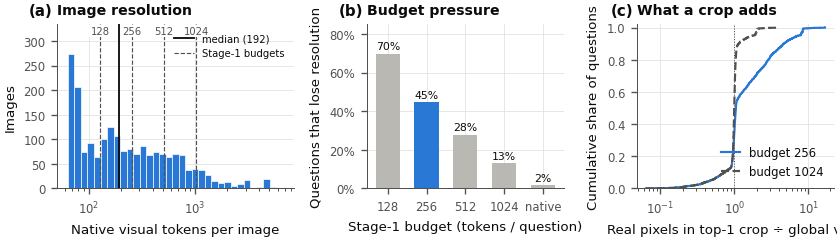

⏱ P1.F1 figure: resolution budget | wall 2.47 s | CPU 2.37 s (0.96 cores, sys 9.0%) | GPU 0.00 s (no GPU used)
figure -> /content/rave_work/figures/fig_p1_2_crop_examples.pdf


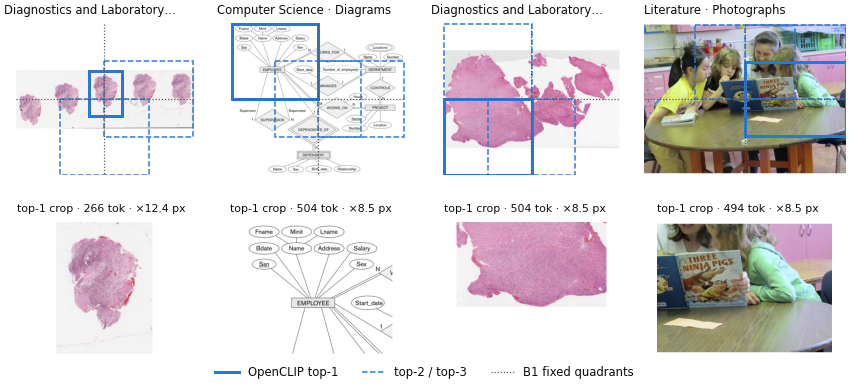

⏱ P1.F2 figure: crop-selection examples | wall 2.68 s | CPU 2.69 s (1.0 cores, sys 10.4%) | GPU 0.00 s (no GPU used)
⏱ cell 12: import textwrap | wall 5.18 s | CPU 5.08 s (0.98 cores, sys 10.9%) | GPU busy 0.00 s [nvml_util], util 0.0%, 0.33 kJ, peak 0.02 GB


In [14]:
import textwrap
import matplotlib.patches as mpatches
from matplotlib.ticker import PercentFormatter

with Phase("P1.F1 figure: resolution budget", budget_min=2):
    fig, axs = plt.subplots(1, 3, figsize=(COL2, 2.2), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
    ax = axs[0]
    nt = IMG.native_tokens.clip(lower=1)
    bins = np.logspace(np.log10(max(nt.min(), 8)), np.log10(nt.max() * 1.05), 34)
    ax.hist(nt, bins=bins, color=COLORS["RAVE_risk"], edgecolor="white", linewidth=0.4)
    ax.set_xscale("log")
    top = ax.get_ylim()[1]
    ax.set_ylim(0, top * 1.16)
    for bgt in GLOBAL_BUDGETS:
        ax.axvline(bgt, color=INK2, lw=0.7, ls="--")
        ax.text(bgt, top * 1.15, str(bgt), ha="center", va="top", fontsize=6, color=INK2,
                bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none"))
    ax.axvline(nt.median(), color=INK, lw=1.1)
    ax.legend(handles=[Line2D([], [], color=INK, lw=1.1, label=f"median ({nt.median():.0f})"),
                       Line2D([], [], color=INK2, lw=0.7, ls="--", label="Stage-1 budgets")],
              loc="upper right", fontsize=6)
    ax.set_xlabel("Native visual tokens per image")
    ax.set_ylabel("Images")
    ax.set_title("Image resolution")
    panel(ax, "a")

    ax = axs[1]
    pct = [100 * (qtok[f"g{b}_tokens"] < qtok.native_tokens).mean() for b in BASES]
    xs = np.arange(len(BASES))
    ax.bar(xs, pct, width=0.62, color=[COLORS["RAVE_risk"] if b == MAIN_BASE else "#b9b8b3" for b in BASES])
    for x, v in zip(xs, pct):
        ax.text(x, v + 1.2, f"{v:.0f}%", ha="center", va="bottom", fontsize=6.5, color=INK)
    ax.set_xticks(xs, BASES)
    ax.set_ylim(0, max(pct + [1]) * 1.22)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xlabel("Stage-1 budget (tokens / question)")
    ax.set_ylabel("Questions that lose resolution")
    ax.set_title("Budget pressure")
    panel(ax, "b")

    ax = axs[2]
    t1 = SEL[SEL.role == "top1"]
    for bgt, colr, ls in ((MAIN_BASE, COLORS["RAVE_risk"], "-"), (PROTOCOL_BASE, INK2, "--")):
        v = np.sort(t1[f"info_gain_{bgt}"].clip(lower=0.05).values)
        ax.step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=colr, ls=ls, lw=1.3,
                label=f"budget {bgt}")
    ax.set_xscale("log")
    ax.axvline(1.0, color=INK2, lw=0.6, ls=":")
    ax.set_xlabel("Real pixels in top-1 crop ÷ global view")
    ax.set_ylabel("Cumulative share of questions")
    ax.set_ylim(0, 1.02)
    ax.legend(loc="lower right", handlelength=1.6)
    ax.set_title("What a crop adds")
    panel(ax, "c")
    fig.tight_layout(w_pad=1.2)
    save_fig(fig, "fig_p1_1_resolution_budget")

with Phase("P1.F2 figure: crop-selection examples", budget_min=2):
    t1i = SEL[SEL.role == "top1"].set_index("qid")
    pool_ex = Q[Q.n_images == 1].assign(ig=lambda d: d.qid.map(t1i[f"info_gain_{MAIN_BASE}"]),
                                        t0=lambda d: d.img_type.map(lambda s_: (json.loads(s_) or ["image"])[0]))
    pool_ex = pool_ex.sort_values(["ig", "qid"], ascending=[False, True])
    ex = pool_ex.drop_duplicates("t0").head(4)
    if len(ex) < 4:
        ex = pd.concat([ex, pool_ex[~pool_ex.qid.isin(ex.qid)]]).head(4)
    def fit_canvas(im, cw, ch):
        # letterbox onto a fixed-aspect white canvas so every panel has the same size
        sc = min(cw / im.size[0], ch / im.size[1])
        w_, h_ = max(1, int(im.size[0] * sc)), max(1, int(im.size[1] * sc))
        canvas = Image.new("RGB", (cw, ch), (255, 255, 255))
        ox, oy = (cw - w_) // 2, (ch - h_) // 2
        canvas.paste(im.resize((w_, h_), Image.LANCZOS), (ox, oy))
        return canvas, sc, ox, oy, w_, h_
    fig, axs = plt.subplots(2, max(1, len(ex)), figsize=(COL2, 3.3), squeeze=False,
                            gridspec_kw=dict(height_ratios=[1.25, 1], hspace=0.28, wspace=0.06))
    for j, r in enumerate(ex.itertuples()):
        k = json.loads(r.images)[0]
        im = load_rgb(raw_by_img[(r.qid, k)])
        disp, sc, ox, oy, w_, h_ = fit_canvas(im, 800, 600)
        ax = axs[0, j]; ax.imshow(disp); ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.plot([ox + w_ / 2] * 2, [oy, oy + h_], color=INK2, lw=0.7, ls=":")
        ax.plot([ox, ox + w_], [oy + h_ / 2] * 2, color=INK2, lw=0.7, ls=":")
        for c in SEL[(SEL.qid == r.qid) & SEL.role.isin(["top3", "top2", "top1"])].sort_values("role", ascending=False).itertuples():
            main = c.role == "top1"
            ax.add_patch(mpatches.Rectangle((ox + c.x0 * sc, oy + c.y0 * sc), (c.x1 - c.x0) * sc, (c.y1 - c.y0) * sc,
                                            fill=False, ec=COLORS["RAVE_risk"], lw=1.8 if main else 0.9,
                                            ls="-" if main else "--"))
        ax.set_xlim(-0.5, 799.5); ax.set_ylim(599.5, -0.5)          # keep every panel exactly the canvas size
        ax.set_title(textwrap.shorten(f"{r.subject.replace('_', ' ')} · {r.t0}", 32, placeholder="…"), fontsize=7,
                     fontweight="normal", loc="left")
        c1 = t1i.loc[r.qid]
        crop_disp = fit_canvas(Image.open(_abs(c1.crop_path)).convert("RGB"), 600, 450)[0]
        ax2 = axs[1, j]; ax2.imshow(crop_disp); ax2.set_xticks([]); ax2.set_yticks([])
        for sp in ax2.spines.values():
            sp.set_visible(False)
        ax2.set_title(f"top-1 crop · {int(c1.crop_tokens)} tok · ×{c1[f'info_gain_{MAIN_BASE}']:.1f} px",
                      fontsize=6.5, fontweight="normal", loc="left")
    handles = [Line2D([], [], color=COLORS["RAVE_risk"], lw=1.8, label="OpenCLIP top-1"),
               Line2D([], [], color=COLORS["RAVE_risk"], lw=0.9, ls="--", label="top-2 / top-3"),
               Line2D([], [], color=INK2, lw=0.7, ls=":", label="B1 fixed quadrants")]
    fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01))
    fig.subplots_adjust(left=0.01, right=0.99, top=0.93, bottom=0.08)
    save_fig(fig, "fig_p1_2_crop_examples")

## Summary — CPU and GPU time of Portion 1

In [15]:
time_report("P1")

[P1] 12 cells | wall 5.7 min | CPU 30.8 CPU-min (5.4 cores avg) | GPU busy 0.71 min (phases) / 0.53 min (cells, NVML) | GPU energy 31.4 kJ


,name,ok,wall_s,cpu_s,cores_used,sys_cpu_util_pct,gpu_busy_s,gpu_busy_src,gpu_util_pct,gpu_energy_J,gpu_peak_alloc_gb,n_forward,budget_min,window_h_used
0,P1.1 load MMMU-Pro standard (10 options),True,25.179,5.689,0.23,15.4,0.000,none,0.0,1395.5,NaN,0.0,10.0,NaN
1,P1.2 parse + dump raw bytes,True,2.409,2.416,1.00,27.1,0.000,none,0.0,134.0,NaN,0.0,5.0,NaN
2,P1.4 global images x5 budgets + candidate boxe...,True,38.568,392.712,10.18,97.3,0.000,none,0.0,2143.5,NaN,0.0,15.0,NaN
3,P1.5a load OpenCLIP,True,15.936,15.708,0.99,9.5,0.087,nvml_util,0.6,899.4,1.71,0.0,5.0,NaN
4,P1.5b CLIP text + crop embeddings,True,52.016,292.882,5.63,39.9,42.421,cuda_events,65.1,13751.1,4.09,91.0,10.0,NaN
5,P1.6 materialise crops + B2 images (threads; P...,True,104.702,989.260,9.45,80.4,0.000,none,0.0,6678.7,0.18,0.0,10.0,NaN
6,P1.7 grouped folds (5 x 3 repeats),True,1.778,1.783,1.00,8.5,0.000,none,0.0,114.1,0.18,0.0,1.0,NaN
7,P1.8 exact sequence lengths (all variants),True,20.882,16.687,0.80,12.0,0.000,none,0.0,1316.9,0.18,0.0,10.0,NaN
8,P1.9 download Qwen/Qwen3-VL-8B-Instruct,True,51.520,104.695,2.03,26.4,0.000,none,0.0,3241.3,0.18,0.0,40.0,NaN
9,P1.10 save artefacts + manifest,True,0.237,0.239,1.01,NaN,0.000,none,NaN,12.6,0.18,0.0,2.0,NaN


⏱ cell 13: time_report("P1") | wall 0.05 s | CPU 0.05 s (0.97 cores, sys None%) | GPU 0.00 s (no GPU used)
